<a href="https://colab.research.google.com/github/shruti18sk/multilingual_slm_tokenisation/blob/main/multilingual_slm_tokenisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q transformers sentencepiece tiktoken protobuf pandas numpy matplotlib

In [2]:
import os
os.makedirs("results", exist_ok=True)
os.makedirs("data", exist_ok=True)

!wget -q -O flores200.tar.gz https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz
!tar -xzf flores200.tar.gz
!ls flores200_dataset/devtest | grep -E "eng_Latn|hin_Deva|kor_Hang"

eng_Latn.devtest
hin_Deva.devtest
kor_Hang.devtest


In [3]:
N = 300

LANGS = {"en": "eng_Latn", "hi": "hin_Deva", "ko": "kor_Hang"}
data = {}
for k, code in LANGS.items():
    with open(f"flores200_dataset/devtest/{code}.devtest", encoding="utf-8") as f:
        data[k] = [line.strip() for line in f][:N]

for k in data:
    print(k, len(data[k]), "|", data[k][0][:80])

en 300 | "We now have 4-month-old mice that are non-diabetic that used to be diabetic," h
hi 300 | उन्होंने कहा “कि अब हमारे पास 4 महीने उम्र वाले चूहे हैं जिन्हें मधुमेह नहीं है 
ko 300 | "그는 ""현재 4개월 된 당뇨병에서 치료된 생쥐가 있다""고 덧붙였다."


In [4]:
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

def token_counts(tok, sents):
    return np.array([len(tok(s, add_special_tokens=False).input_ids) for s in sents])

def stats(tok, sents):
    toks = token_counts(tok, sents)
    words = np.array([len(s.split()) for s in sents])
    nbytes = np.array([len(s.encode("utf-8")) for s in sents])
    return toks, toks / words, nbytes / toks

def boot_ci(x, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = [rng.choice(x, len(x), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

In [5]:
MODELS = [
    "Qwen/Qwen2.5-1.5B",
    "HuggingFaceTB/SmolLM2-1.7B",
    "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
]

rows = []
for m in MODELS:
    print("Running:", m)
    tok = AutoTokenizer.from_pretrained(m)
    en_toks = token_counts(tok, data["en"])
    for lang in ["en", "hi", "ko"]:
        t, fert, bpt = stats(tok, data[lang])
        parity = t / en_toks          # parallel sentences, isliye per-sentence ratio
        lo, hi = boot_ci(parity)
        rows.append(dict(
            model=m.split("/")[-1], lang=lang,
            parity=parity.mean(), ci_lo=lo, ci_hi=hi,
            fertility=fert.mean(), bytes_per_token=bpt.mean(),
            avg_tokens=t.mean()
        ))

df = pd.DataFrame(rows)
df.to_csv("results/token_ratio.csv", index=False)
df.round(2)

Running: Qwen/Qwen2.5-1.5B


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (11 outputs left out)

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

,model,lang,parity,ci_lo,ci_hi,fertility,bytes_per_token,avg_tokens
0,Qwen2.5-1.5B,en,1.00,1.00,1.00,1.32,4.76,27.53
1,Qwen2.5-1.5B,hi,4.40,4.30,4.51,4.76,2.77,119.05
2,Qwen2.5-1.5B,ko,1.71,1.68,1.75,3.13,3.41,46.49
3,SmolLM2-1.7B,en,1.00,1.00,1.00,1.34,4.69,27.98
4,SmolLM2-1.7B,hi,5.09,4.98,5.22,5.59,2.36,139.58
5,SmolLM2-1.7B,ko,4.83,4.73,4.94,8.89,1.19,132.32
6,TinyLlama-1.1B-Chat-v1.0,en,1.00,1.00,1.00,1.50,4.19,31.37
7,TinyLlama-1.1B-Chat-v1.0,hi,4.55,4.45,4.66,5.59,2.36,139.79
8,TinyLlama-1.1B-Chat-v1.0,ko,3.23,3.16,3.30,6.64,1.59,98.89


In [6]:
MODELS = [
    "Qwen/Qwen2.5-1.5B",
    "HuggingFaceTB/SmolLM2-1.7B",
    "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
]

rows = []
for m in MODELS:
    print("Running:", m)
    tok = AutoTokenizer.from_pretrained(m)
    en_toks = token_counts(tok, data["en"])
    for lang in ["en", "hi", "ko"]:
        t, fert, bpt = stats(tok, data[lang])
        parity = t / en_toks          # parallel sentences, isliye per-sentence ratio
        lo, hi = boot_ci(parity)
        rows.append(dict(
            model=m.split("/")[-1], lang=lang,
            parity=parity.mean(), ci_lo=lo, ci_hi=hi,
            fertility=fert.mean(), bytes_per_token=bpt.mean(),
            avg_tokens=t.mean()
        ))

df = pd.DataFrame(rows)
df.to_csv("results/token_ratio.csv", index=False)
df.round(2)

Running: Qwen/Qwen2.5-1.5B
Running: HuggingFaceTB/SmolLM2-1.7B
Running: TinyLlama/TinyLlama-1.1B-Chat-v1.0


,model,lang,parity,ci_lo,ci_hi,fertility,bytes_per_token,avg_tokens
0,Qwen2.5-1.5B,en,1.00,1.00,1.00,1.32,4.76,27.53
1,Qwen2.5-1.5B,hi,4.40,4.30,4.51,4.76,2.77,119.05
2,Qwen2.5-1.5B,ko,1.71,1.68,1.75,3.13,3.41,46.49
3,SmolLM2-1.7B,en,1.00,1.00,1.00,1.34,4.69,27.98
4,SmolLM2-1.7B,hi,5.09,4.98,5.22,5.59,2.36,139.58
5,SmolLM2-1.7B,ko,4.83,4.73,4.94,8.89,1.19,132.32
6,TinyLlama-1.1B-Chat-v1.0,en,1.00,1.00,1.00,1.50,4.19,31.37
7,TinyLlama-1.1B-Chat-v1.0,hi,4.55,4.45,4.66,5.59,2.36,139.79
8,TinyLlama-1.1B-Chat-v1.0,ko,3.23,3.16,3.30,6.64,1.59,98.89


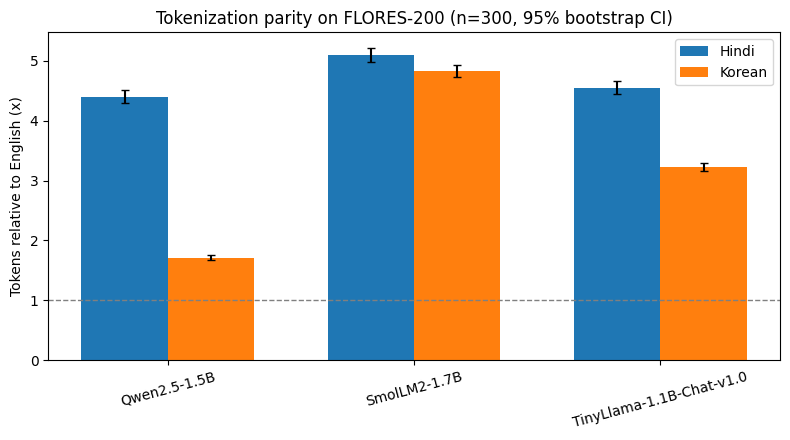

In [7]:
import matplotlib.pyplot as plt

d = df[df.lang != "en"]
models = d.model.unique()
x = np.arange(len(models)); w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, lang in enumerate(["hi", "ko"]):
    s = d[d.lang == lang].set_index("model").loc[models]
    err = [s.parity - s.ci_lo, s.ci_hi - s.parity]
    ax.bar(x + (i - 0.5) * w, s.parity, w, yerr=err, capsize=3,
           label={"hi": "Hindi", "ko": "Korean"}[lang])

ax.axhline(1, color="gray", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(models, rotation=15)
ax.set_ylabel("Tokens relative to English (x)")
ax.set_title(f"Tokenization parity on FLORES-200 (n={N}, 95% bootstrap CI)")
ax.legend(); plt.tight_layout()
plt.savefig("results/parity_plot.png", dpi=200)
plt.show()

In [8]:
pilot = pd.DataFrame({
    "model": ["Qwen2.5-1.5B", "TinyLlama-1.1B-Chat-v1.0", "SmolLM2-1.7B"],
    "ko_pilot": [1.86, 3.64, 5.50],
    "hi_pilot": [4.76, 5.18, 5.86],
})
new = df[df.lang != "en"].pivot(index="model", columns="lang", values="parity").round(2).reset_index()
new.columns = ["model", "hi_flores", "ko_flores"]
pilot["model"] = pilot["model"].replace({"Qwen2.5-1.5B": "Qwen2.5-1.5B",
                                         "SmolLM2-1.7B": "SmolLM2-1.7B"})
pilot.merge(new, on="model", how="left")

,model,ko_pilot,hi_pilot,hi_flores,ko_flores
0,Qwen2.5-1.5B,1.86,4.76,4.40,1.71
1,TinyLlama-1.1B-Chat-v1.0,3.64,5.18,4.55,3.23
2,SmolLM2-1.7B,5.50,5.86,5.09,4.83
